# Machine Learning: Exercise session 03

In this exercise session we will focus mainly on model assessment. You will learn how to use and apply some of the error estimation techniques seen in class, using scikit-learn (parts 1 and 2).

To illustrate these techniques in context, we will continue where we left out in exercise session 01, with the housing dataset. You can export and use your resulting, cleaned, dataframe from the first session, or you can download it on moodle in this week's section (with the cleaning and feature engineering from the first session already performed).

The third part of this notebook will introduce scikit-learn's Pipelines, which are a very useful tool that can be used, among other things, to avoid validation overfitting during cross-validation.

Due to this last part making the practical part a bit longer, there will be no "theoretical" exercise this week.

## 0. Introduction and Setup

In [1]:
import matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd

Import the clean housing dataset with `pd.read_csv` and take a quick look at it, to verify that it is in the desired shape (display the dataframe, check its "infos").

In [4]:
housing = pd.read_csv('housing_clean.csv')

In [6]:
housing.head()

,longitude,latitude,housing_median_age,median_income,median_house_value,rooms_per_bedroom,rooms_per_household,people_per_household,ocean_proximity_enc
0,-122.23,37.88,41.0,8.3252,452600.0,6.821705,6.984127,2.555556,3.0
1,-122.22,37.86,21.0,8.3014,358500.0,6.418626,6.238137,2.109842,3.0
2,-122.24,37.85,52.0,7.2574,352100.0,7.721053,8.288136,2.802260,3.0
3,-122.25,37.85,52.0,5.6431,341300.0,5.421277,5.817352,2.547945,3.0
4,-122.25,37.85,52.0,3.8462,342200.0,5.810714,6.281853,2.181467,3.0


Separate the dataframe into the features `X` and the target variable `y`: (remember, we want to predict the median house value, given the other variables)

In [7]:
X = housing.drop('median_house_value', axis=1)
y = housing['median_house_value']

## 1. Fitting KNN and expected error

In [8]:
from sklearn.neighbors import KNeighborsRegressor

The goal of the following sections will not only be to use a k-Nearest neighbors regression model in order to predict the expected median household values, based on the other features, but also to assess how our model is performing, that is, its expected prediction error.

To begin with, import the same KNN regression model that you briefly used in the first exercise session, and fit it on the whole dataset for the desired prediction task. Use as a hyper-parameter `k=1` neighbors.

In [11]:
k = 1
knn = KNeighborsRegressor(n_neighbors=k)
knn.fit(X, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


Now, evaluate its root mean squared error using `X` and `y`.

In [10]:
from sklearn.metrics import root_mean_squared_error

In [13]:
rms = root_mean_squared_error(y, knn.predict(X))
print(f"Root Mean Squared Error: {rms}")


Root Mean Squared Error: 0.0


What do you observe? What does that say probably say about the model? Does that mean that the model is performing well, you think?

The model is probably overfitting as it has a RMS of 0 meaning it learned to correctly preditict all the training data with out a sing error.

### 1.1. Train-test split

Now, separate the data into `X_train` `y_train` and `X_test` `y_test`, and fit a KNN regressor on the training set

In [14]:
from sklearn.model_selection import train_test_split

In [15]:
# fill out the ??
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = .2, random_state = 42)

In [ ]:
k = 1
knn = KNeighborsRegressor(n_neighbors=k)
knn.fit(X_train, y_train)


Root Mean Squared Error: 76810.40920964915


Check its RMSE both on the training and on the test set, do you observe something that you expected?

In [17]:
rms_train = root_mean_squared_error(y_train, knn.predict(X_train))
print(f"Root Mean Squared Error on training data: {rms_train}") 

Root Mean Squared Error on training data: 0.0


In [18]:
rms_test = root_mean_squared_error(y_test, knn.predict(X_test))
print(f"Root Mean Squared Error on test data: {rms_test}")

Root Mean Squared Error on test data: 76810.40920964915


You've learned about the Bias-Variance tradeoff during the last lecture. Does the model suffer from too much bias or too much variance? Does that mean that it is too "flexible", or not enough?

### 1.2. Cross-validation

When fitting a model, we are interested in its expected generalization error (the expected error on unseen data).
In order to estimate this expected error, a more stable way to estimate it than with a train-test split is to use cross-validation.

Declare a new KNN regressor instance with the same hyper-parameter as before, and estimate its expected generalization error with 10 folds cross-validation on `X` and `y`.

Print the average generalization RMSE for each fold as well as the cross-validation error estimate.


_Remark:_ during fitting sklearn maximizes "scores" instead of minimizing losses, that is why we specify `scoring="neg_mean_squared_error"` below, as we maximize the negative MSE instead of minimizing the MSE.

In [19]:
from sklearn.model_selection import cross_val_score

In [27]:
knn = KNeighborsRegressor(n_neighbors=1)
CVscores = cross_val_score(knn, X, y, scoring="neg_mean_squared_error", cv=10)
cv_rmse = np.sqrt(-CVscores)
print(f"CV RMSE: {cv_rmse.mean():.0f} ± {cv_rmse.std():.0f}")

CV RMSE: 85856 ± 14991


In [24]:
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",1
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [25]:
rms = root_mean_squared_error(y_test, knn.predict(X_test))
print(f"Root Mean Squared Error: {rms}")


Root Mean Squared Error: 76810.40920964915


Note in `cross_val_score` you can simply specify the number of folds with the argument `cv=10`. By default, sklearn splits the data equally into the specified number of folds without shuffling it first. This behaviour might be useful when, for example, some time dependence between observations needs to be kept for specific models. However, if we assume that the observations are independent, it might be a better idea to shuffle observations (rows) before splitting, to avoid imbalances within folds, created by any kind of prior implicit sorting of the observations.

You can control the splitting method and, in particular, shuffle the data prior to splitting in folds, by specifying a [KFold object](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators) instead of a simple number for the `cv` argument.

Repeat the cross-validation estimation by, this time, shuffling the data for the folds split. Do you notice any difference with the estimated RMSEs for each fold? If yes, why do you think (speculate) it might be?

In [26]:
from sklearn.model_selection import KFold

In [28]:
knn = KNeighborsRegressor(n_neighbors=1)
folds = KFold(n_splits=10 , shuffle=True, random_state=1)
CVscores = cross_val_score(knn, X, y, scoring="neg_mean_squared_error", cv=folds)

In [29]:
cv_rmse = np.sqrt(-CVscores)
print(f"CV RMSE: {cv_rmse.mean():.0f} ± {cv_rmse.std():.0f}")

CV RMSE: 74431 ± 2201


## 2. Hyper-Parameter tuning and Cross-validation

In the first part, we "arbitrarily" chose a hyper-parameter value for our model. However, this value might not be optimal. Usually, we want to compare the model's expected error for a range of different possible hyper-parameters, in order to choose the best one for the task at hand. (Remember the optimal value depends on the specific data we try to model, and there cannot be a "best" hyper-parameter value overall, this is often called the *no free lunch theorem*.)

In sklearn, [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) performs a grid-search over the given range of hyper-parameter values, by estimating the cross-validation error for each value in the given grid.

In [30]:
from sklearn.model_selection import GridSearchCV, KFold

First, instanciate a new kNN regressor (no need to specify a k value), and specify the grid of hyper-parameter values in a dictionary of the form `{"hyper_param_name" : values_to_try}`.

Choose equally spaced values between $1$ and $49$, with an increment of $2$ as a grid of values to try.

In [40]:
knn = KNeighborsRegressor()

hyper_parameters = {"n_neighbors": range(1,15)}

Now perform the Grid-search with 10-fold cross-validation, to estimate the model's generalization error for the chosen grid of k values. Don't forget to shuffle the data for the fold split.

_Hint:_ `GridSearchCV` is an object, you need to instanciate it and fit it (like a ML model).

_Warning_: This might take a long time, depending on your computer.
You can reduce the number of folds or the number of k values to try, if you want to speed it up.

In [41]:
knnCV = GridSearchCV(estimator=knn, param_grid=hyper_parameters, scoring="neg_mean_squared_error",
                       cv=KFold(n_splits=10, shuffle=True, random_state=1))
knnCV.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",KNeighborsRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'n_neighbors': range(1, 15)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of i

The fitted grid-search object has an attribute `cv_results_` containing the grid search results as a dictionary. Inspect its contents and try to understand what each variable means. (It might be easier to visualize if you convert the dictionary into a DataFrame.)

In [42]:
print(knnCV.cv_results_)

{'mean_fit_time': array([0.00675735, 0.00608459, 0.00597138, 0.00599153, 0.00644751,
       0.00600717, 0.00601006, 0.00588217, 0.00588775, 0.00601091,
       0.00592997, 0.00592847, 0.0059221 , 0.00594389]), 'std_fit_time': array([1.49828532e-03, 2.06423026e-04, 1.68682545e-04, 2.28103767e-04,
       4.16667144e-04, 1.02634502e-04, 1.83577723e-04, 9.87420958e-05,
       1.34953677e-04, 1.61519682e-04, 8.49102557e-05, 1.09066158e-04,
       4.86545030e-05, 8.85552368e-05]), 'mean_score_time': array([0.01411936, 0.01741953, 0.01966581, 0.02137983, 0.02331297,
       0.02876339, 0.02504201, 0.02616601, 0.02713561, 0.02836547,
       0.02942348, 0.03021059, 0.03088727, 0.03195651]), 'std_score_time': array([0.00055269, 0.000591  , 0.00122188, 0.00102088, 0.00040465,
       0.01395155, 0.00049483, 0.0003595 , 0.00032133, 0.00067122,
       0.00076263, 0.00060232, 0.00070846, 0.00037189]), 'param_n_neighbors': masked_array(data=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14],
             m

Now, using the `GridSearchCV` results that you inspected, extract the k value yielding the "best" (lowest) MSE estimate

(Again fill out the `??` below)

In [43]:
resCV = knnCV.cv_results_

test_MSEs = -resCV["mean_test_score"]
std_test_MSEs = resCV["std_test_score"]
k_grid = resCV["param_n_neighbors"].data

index_best = np.argmin(test_MSEs)  # index of the k value with the lowest MSE estimate
best_k = k_grid[index_best]

Now extract the more parsimonious k value obtained by the "one standard error rule" seen in class.

_Hint_: You might first need to answer this question: *Are larger or smaller k values yielding a more parsimonious model (low "flexibility" and variance)?*

In [44]:
one_se_rule_best_k = k_grid[np.argmin(test_MSEs + std_test_MSEs)]

To better visualize how the expected error varies as a function of the hyper-parameter k, we can construct a MSE plot with standard deviations from the `GridSearchCV`. It is also nice to highlight the two important k values discussed just above (with vertical lines for example).

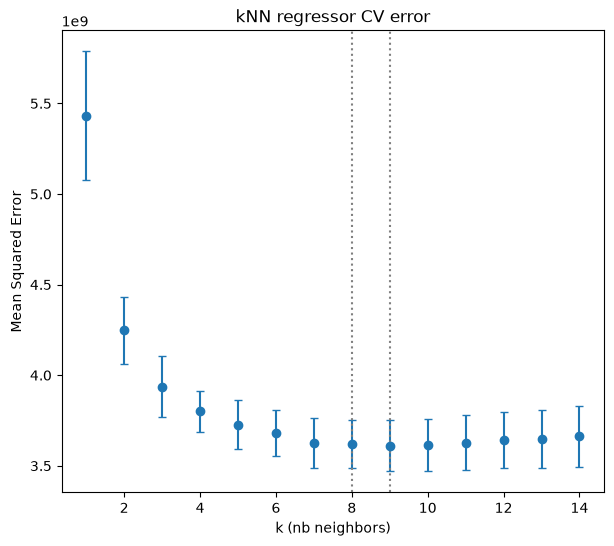

In [45]:
plt.figure(figsize=(7,6))
plt.errorbar(x=k_grid, y=test_MSEs, yerr=std_test_MSEs, fmt='o', capsize=3)

plt.axvline(best_k, ls='dotted', color="grey")#vertical line at the k yielding minimum CV MSE
plt.axvline(one_se_rule_best_k, ls='dotted', color="grey")#vertical line at best k value according to 1 std err rule

plt.title("kNN regressor CV error")
plt.xlabel('k (nb neighbors)')
plt.ylabel('Mean Squared Error')
plt.show()

To conclude, how does the expected generalization error of the model with the newly selected k value compare to our initial k choice, prior to cross-validation based selection?

And for the other k values, how to you think the training error compares to the CV error. You can compare them by adding the training error as a function of the hyper-parameter value to the plot above. (*Hint: [GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html) can return the training scores, but it is more expensive computationally. You can also compute them yourself easily on X and y by iterating over the k_grid.*)

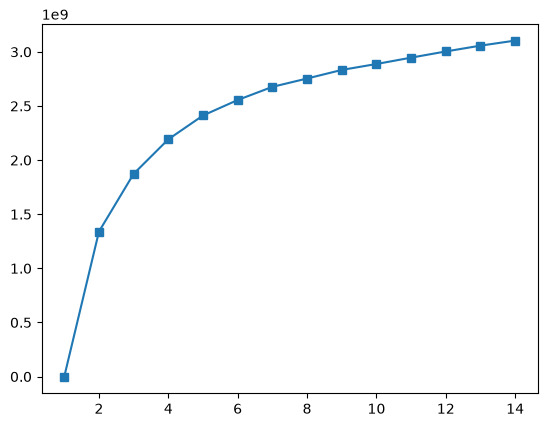

In [49]:
train_MSEs = []
for k in k_grid:
    knn = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
    train_MSEs.append((root_mean_squared_error(y_train, knn.predict(X_train)))**2)

plt.plot(k_grid, train_MSEs, marker="s", label="Training FMSE")

You can now fit the model, with the newly selected k value to the whole dataset. This will be the final kNN model, chosen based on empirical evidence :)

In [50]:
knn_final = KNeighborsRegressor(n_neighbors=best_k)
knn_final.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",np.int64(9)
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


_Remark:_ KNN was used as an example in this session, but we could also do the same with any other machine learning model.

## 3. Pipelines and cross-validation

### 3.1 Motivation

There is one essential detail that has been left-out in the first two parts of this notebook.
As kNN relies on euclidean distance to select the nearest points, it is always better to work with standardized data (each variable rescaled to be centered at 0 and have unit variance). That way the same distance along each feature axis is proportional for each variable.

As you've seen in the first week's tutorial, you can use [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) to rescale the variables.

When you leave some validation/test data out to evaluate your model, it is best practice to **not use it for any type of estimation**, to avoid having a biased error estimate (as, otherwise, you already "took" some information from the validation data). This also holds for estimating the mean and standard deviation of variables, with the `StandardScaler`.

Here is an example of how to scale the data properly, in case of a train-test split, without overfitting the test set:

In [51]:
from sklearn.preprocessing import StandardScaler

#Create the scaler:
scaler = StandardScaler()

#Estimate the mean and variances for each variable on the training set only:
scaler.fit(X_train)

print("Original means:", scaler.mean_)
print("Original Variances:", scaler.var_)

#Scale the training and test features, using the previously estimated means and variances
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

Original means: [-119.58051328   35.64056895   28.61501285    3.87069684    4.98214201
    5.42498593    3.10022784    1.17117338]
Original Variances: [  4.02337913   4.56298874 158.175595     3.60151825   1.37041922
   5.56867348 135.72595174   2.02796139]


We could then fit our kNN model on the scaled training set and evaluate it on the test set, without having "cheated", by using information from the test set in our estimations.

If you now think about estimating the error using cross-validation, you'll quickly realize that not overfitting with the scaler gets a bit more complicated, as we need to perform the above procedure separately for each fold, before fitting the model. That is when Pipelines come into play.

### 3.2. Cross-validation with Pipelines

In a [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html) you can define sequentially, all the steps of your transformation + fitting process. For example standard scaling + kNN. The syntax is the following (complete the ??): 

_Hint_: each step in the pipeline is defines as a tuple: `("desired_step_name", Transformer_or_predictor_object)`

In [52]:
from sklearn.pipeline import Pipeline

In [53]:
knn_pipe = Pipeline([("scaler", StandardScaler()),
                     ("kNN", KNeighborsRegressor())])

You can then fit the entire Pipeline on the training set, and predict on the test set, as if it was a single model:

In [54]:
knn_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('kNN', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['longitude','latitude','housing_median_age',...,'rooms_per_household', 'people_per_household','ocean_proximity_enc']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


Now repeat the grid-search (section 2, except the training error question) by using the new Pipeline instead of the simple kNN as a model.

_Hint 1:_ There shouldn't be too many changes in the code.

_Hint 2:_ You'll need to add the pipeline step name before the parameter name for the grid in `GridSearchCV`. (i.e. replace `"n_estimators"` by `"kNN__n_estimators"`).

In [55]:
#Declare Pipe and grid:
pipe = Pipeline([("scaler", StandardScaler()),
                 ("kNN", KNeighborsRegressor())])

param_grid = {"kNN__n_neighbors": range(1,15)}

In [56]:
#Declare and fit the grid search:
grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring='neg_mean_squared_error')
grid_search.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'kNN__n_neighbors': range(1, 15)}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information prin

In [57]:
#Compute "best" k value and its index:
best_k = grid_search.best_params_['kNN__n_neighbors']


In [58]:
#compute best k based on one std error rule:
best_k_one_std = grid_search.best_params_['kNN__n_neighbors']

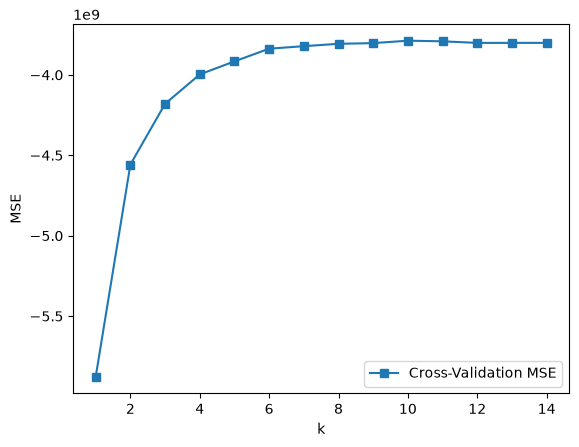

In [59]:
#Plot the grid-search results:
plt.plot(param_grid['kNN__n_neighbors'], grid_search.cv_results_['mean_test_score'], marker="s", label="Cross-Validation MSE")
plt.xlabel("k")
plt.ylabel("MSE")
plt.legend()
plt.show()

In [60]:
#Fit the final model:
knn_final = KNeighborsRegressor(n_neighbors=best_k)
knn_final.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}
